<a href="https://colab.research.google.com/github/gyeongee/TIL/blob/main/%EC%8B%AC%EC%B8%B5%EC%8B%A0%EA%B2%BD%EB%A7%9D%EC%9D%84_%ED%99%9C%EC%9A%A9%ED%95%9C_%EC%9D%B4%EC%A7%84%EB%B6%84%EB%A5%98.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

로지스틱 회귀 모델은 사실 선형 회귀 모델에 단순하게 마지막 활성 함수를 시그모이드로 추가해 준 것이라고 볼 수 있습니다.

BCE 손실 함수를 미분할 때 체인 룰을 통해 역전파가 적용되고 각 가중치 파라미터별로 경사하강법이 적용되는 것을 제외하면 모두 똑같이 동작할 것입니다.

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [91]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from tqdm import tqdm

In [92]:
from sklearn.datasets import load_breast_cancer

cancer=load_breast_cancer()

df=pd.DataFrame(data=cancer.data,columns=cancer.feature_names)
df['target']=cancer.target

df.head(3)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0


In [93]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [94]:
df['target'].value_counts()

,count
target,
1,357
0,212


In [95]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


### 데이터 분리 후에 정규화를 진행해 보자

이진 분류이므로 타겟 데이터는 정규화 진행 x !

In [96]:
data=torch.from_numpy(df.values).float()
X=data[:,:-1]
y=data[:,-1:]

from sklearn.model_selection import train_test_split
# 학습,검증,테스트 데이터 분리
# 6:2:2 로 분리
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=5)
X_train,X_valid,y_train,y_valid=train_test_split(X_train,y_train,test_size=0.25,random_state=5)

print(X_train.shape,X_valid.shape,X_test.shape)
print(y_train.shape,y_valid.shape,y_test.shape)

torch.Size([341, 30]) torch.Size([114, 30]) torch.Size([114, 30])
torch.Size([341, 1]) torch.Size([114, 1]) torch.Size([114, 1])


In [97]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
# X_train으로 학습하고
scaler.fit(X_train.numpy())

# target깂 제외하고 정규화 진행
X_train=torch.from_numpy(scaler.transform(X_train.numpy())).float()
X_valid=torch.from_numpy(scaler.transform(X_valid.numpy())).float()
X_test=torch.from_numpy(scaler.transform(X_test.numpy())).float()

print(X_train.shape, X_valid.shape,X_test.shape)



torch.Size([341, 30]) torch.Size([114, 30]) torch.Size([114, 30])


In [98]:
model=nn.Sequential(
    nn.Linear(X_train.size(-1),25),
    nn.ReLU(),
    nn.Linear(25,20),
    nn.ReLU(),
    nn.Linear(20,15),
    nn.ReLU(),
    nn.Linear(15,10),
    nn.ReLU(),
    nn.Linear(10,5),
    nn.ReLU(),
    nn.Linear(5,y_train.size(-1)),
    # 최종 출력은 sigmoid를 적용하여 0~1 사이 값 반환(이진 분류)
    nn.Sigmoid(),

)

In [99]:
optimizer=optim.Adam(model.parameters())
optimizer

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)

In [100]:
from copy import deepcopy
n_epochs=10000
batch_size=32
print_interval=10
early_stop=100

best_model=None
lowest_loss=np.inf
lowest_epoch=np.inf

In [101]:
# epoch마다 학습/검증 손실값 저장하는 list
train_history,val_history=[],[]

for i in tqdm(range(n_epochs)):
  indices=torch.randperm(X_train.size(0))

  X_=torch.index_select(X_train,dim=0,index=indices)
  y_=torch.index_select(y_train,dim=0,index=indices)

  X_=X_.split(batch_size,dim=0)
  y_=y_.split(batch_size,dim=0)

  # 훈련데이터 손실,검증 데이터 손실 값 저장
  train_loss,val_loss=0,0
  # 예측값 저장
  pred_y=[]

  for X_i,y_i in zip(X_,y_):
    pred_y_i=model(X_i)
    # sigmoid를 적용했기 때문에 binary_cross_entropy() 사용
    loss=F.binary_cross_entropy(pred_y_i,y_i)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += float(loss)
  train_loss=train_loss/len(X_)


  with torch.no_grad():
    X_=X_valid.split(batch_size,dim=0)
    y_=y_valid.split(batch_size,dim=0)

    for X_i,y_i in zip(X_,y_):
      pred_y_i=model(X_i)
      loss=F.binary_cross_entropy(pred_y_i,y_i)
      val_loss+=loss
      pred_y.append(pred_y_i)

    val_loss=val_loss/len(X_)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if (i+1) % print_interval == 0:
      print(f'Epoch :{i+1} train_loss={train_loss:.4e}\
      valid_loss:{val_loss:.4e}, lowest_loss:{lowest_loss:.4e}')

    if val_loss < lowest_loss:
      lowest_loss =val_loss
      lowest_epoch=i

      best_model = deepcopy(model)
    else:

      if early_stop >0 and lowest_epoch + early_stop < i+1:
          print(f"early_stop:{early_stop}")
          break

print(f'{lowest_epoch+1}epoch애서 가장 낮은 검증 손실값:{lowest_loss:.4e}')
model.load_state_dict(best_model.state_dict())

  0%|          | 12/10000 [00:00<06:20, 26.23it/s]

Epoch :10 train_loss=2.5121e-01      valid_loss:1.4890e-01, lowest_loss:2.5944e-01


  0%|          | 23/10000 [00:01<08:12, 20.24it/s]

Epoch :20 train_loss=5.7741e-02      valid_loss:1.9372e-02, lowest_loss:1.9461e-02


  0%|          | 32/10000 [00:01<08:01, 20.70it/s]

Epoch :30 train_loss=4.0926e-02      valid_loss:1.2013e-02, lowest_loss:1.2785e-02


... (21 outputs left out)

Epoch :140 train_loss=1.2726e-04      valid_loss:3.7302e-02, lowest_loss:5.6691e-03


  1%|▏         | 148/10000 [00:05<06:27, 25.41it/s]

early_stop:100
49epoch애서 가장 낮은 검증 손실값:5.6691e-03


<All keys matched successfully>

In [102]:
# 신경망 학습 구현(이진분류)
train_history, val_history = [],[]

for i in range(n_epochs):
  indices = torch.randperm(X_train.size(0))
  X_ = torch.index_select(X_train, dim=0, index=indices)
  y_ = torch.index_select(y_train, dim=0, index=indices)

  X_ = X_.split(batch_size,dim=0)
  y_ = y_.split(batch_size,dim=0)

  train_loss , val_loss = 0,0
  pred_y =[]

  for X_i, y_i in zip(X_,y_):
    # 예측값 생성
    pred_y_i= model(X_i)
    # sigmoid를 적용했기 때문에 binary_cross_entropy() 사용
    loss = F.binary_cross_entropy(pred_y_i, y_i)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_loss += float(loss)
  #평균
  train_loss=train_loss/len(X_)

  with torch.no_grad():
    X_ = X_valid.split(batch_size, dim = 0)
    y_ = y_valid.split(batch_size, dim = 0)

    for X_i, y_i in zip(X_,y_):
      pred_y_i= model(X_i)
      # sigmoid를 적용했기 때문에 binary_cross_entropy() 사용
      loss = F.binary_cross_entropy(pred_y_i, y_i)
      val_loss+=loss
      # valid의 예측값들을 pred_y 리스트에 추가
      pred_y.append(pred_y_i)

    val_loss = val_loss/len(X_)

    train_history.append(train_loss)
    val_history.append(val_loss)

    if (i+1) % print_interval == 0 :
      print(f"Epoch: {i+1} : train_loss = {train_loss:.4e} \
             valid_loss = {val_loss:.4e}, lowest_loss : {lowest_loss:.4e}")


    if val_loss < lowest_loss:
      lowest_loss = val_loss
      lowest_epoch = i

      best_model = deepcopy(model)

    else:
      if early_stop > 0 and lowest_epoch + early_stop < i+1:
        print(f"early_stop:{early_stop}") #epoch 동안 개선되지 않음
        break
print(f" {lowest_epoch + 1}epoch에서 가장 낮은 검증 손실값 :{lowest_loss:.4e}")
model.load_state_dict(best_model.state_dict())





Epoch: 10 : train_loss = 2.5876e-03              valid_loss = 1.2633e-02, lowest_loss : 5.4587e-03
Epoch: 20 : train_loss = 8.3089e-04              valid_loss = 2.1618e-02, lowest_loss : 5.4587e-03
Epoch: 30 : train_loss = 4.9085e-04              valid_loss = 2.6220e-02, lowest_loss : 5.4587e-03
Epoch: 40 : train_loss = 2.4795e-04              valid_loss = 3.0537e-02, lowest_loss : 5.4587e-03
Epoch: 50 : train_loss = 1.7044e-04              valid_loss = 3.5203e-02, lowest_loss : 5.4587e-03
Epoch: 60 : train_loss = 1.2435e-04              valid_loss = 3.8337e-02, lowest_loss : 5.4587e-03
Epoch: 70 : train_loss = 9.7664e-05              valid_loss = 3.9811e-02, lowest_loss : 5.4587e-03
Epoch: 80 : train_loss = 7.6436e-05              valid_loss = 4.3411e-02, lowest_loss : 5.4587e-03
Epoch: 90 : train_loss = 6.4002e-05              valid_loss = 4.5022e-02, lowest_loss : 5.4587e-03
Epoch: 100 : train_loss = 5.3105e-05              valid_loss = 4.6815e-02, lowest_loss : 5.4587e-03
early_sto

<All keys matched successfully>

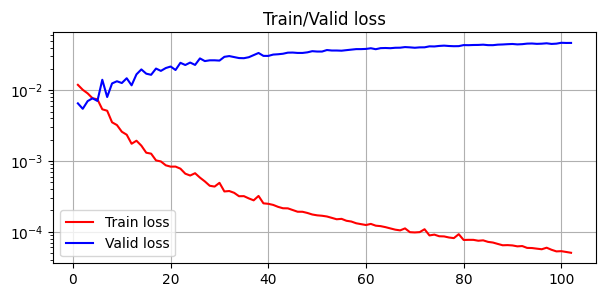

In [103]:
# 손실함수 곡선 확인
plt.figure(figsize=(7,3))
plt.grid(True)
plt.title('Train/Valid loss')

plt.plot(range(1,len(train_history)+1),train_history,label= 'Train loss',color='r')
plt.plot(range(1,len(val_history)+1),val_history,label= 'Valid loss',color='b')

plt.legend()
# 로그 스케일 : 값의 차이가 클 때 데이터를 시각화하기 위해 (10^0~10^6)
plt.yscale('log')
plt.show()



In [104]:
# test 모델 가져다 모델의 성능 평가
test_loss = 0
pred_y = []

# 평가 단계, 경사 하강 x
with torch.no_grad():
  X_ = X_test.split(batch_size, dim=0)
  y_ = y_test.split(batch_size, dim=0)

  for X_i,y_i in zip(X_,y_):
    # 모델 데이터-예측
    pred_y_i = model(X_i)
    # 이진분류 오차 계산 공식 연결해서 loss
    loss = F.binary_cross_entropy(pred_y_i,y_i)
    # loss 값 누적
    test_loss += loss
    # 지난시간에는 += 연산자를 활용해서 진행했음
    # test_loss을 pred_y에 저장
    pred_y.append(pred_y_i)

  # test_loss 누적 결과를 평균값으로 변경하여 초기화
  test_loss = test_loss/len(X_)

  # 예측 데이터 병합
  # 병합함수:torch.cat()
  pred_y = torch.cat(pred_y,dim=0) # dim=0 생략 가능

In [105]:
pred_y

tensor([[7.7168e-12],
        [9.9896e-01],
        [9.9930e-01],
        [9.9991e-01],
        [9.9982e-01],
        [1.8153e-22],
        [9.9946e-01],
        [1.0000e+00],
        [9.9866e-01],
        [9.9998e-01],
        [9.8674e-01],
        [9.8169e-01],
        [9.4730e-24],
        [9.9956e-01],
        [9.9999e-01],
        [1.0000e+00],
        [9.9881e-01],
        [1.0000e+00],
        [1.0000e+00],
        [9.9966e-01],
        [7.4411e-07],
        [1.0000e+00],
        [9.9999e-01],
        [9.9990e-01],
        [1.0000e+00],
        [9.9990e-01],
        [9.5993e-01],
        [1.6148e-19],
        [9.9733e-01],
        [5.6321e-14],
        [1.2243e-27],
        [7.7312e-08],
        [2.2932e-02],
        [1.0544e-09],
        [9.9998e-01],
        [1.0000e+00],
        [1.0448e-08],
        [9.9974e-01],
        [9.9986e-01],
        [6.5477e-19],
        [9.9459e-01],
        [9.9998e-01],
        [1.0000e+00],
        [1.3267e-11],
        [9.9997e-01],
        [9

In [106]:
print(f"Test Loss: {test_loss}")

Test Loss: 0.10509476065635681


In [107]:
# 일반화가 된건가?
history_info = list(zip(train_history, val_history))
history_info
# 검증손실(valid_loss)을 기준으로 오름차순 정렬함
# 가장 작은 검증 손실이 맨 앞에 오도록 정렬함
# list.sort()
sort_history = sorted(history_info,key = lambda x:x[1])
sort_history
print(f"train_loss:{sort_history[0][0]}")
print(f"train_loss:{sort_history[0][0]:.4e}")

print(f"valid_loss:{sort_history[0][1]}")
print(f"valid_loss:{sort_history[0][1]:.4e}")
print(f"Test_loss:{test_loss:4e}")
# 기존 검증 데이터보다는 오차값이 많이 발생하고 있음

train_loss:0.010138196833643386
train_loss:1.0138e-02
valid_loss:0.005458739586174488
valid_loss:5.4587e-03
Test_loss:1.050948e-01


In [108]:
# 예측하고자하는 0,1을 얼마나 잘 맞췄는가 비교 accuracy(정확도) 출력
correct_count=(y_test == (pred_y > 0.5)).sum()
accuracy = correct_count/len(y_test)
print(accuracy) # 97% 정도로 예측이 진행됨


tensor(0.9825)


In [110]:
df = pd.DataFrame(torch.cat([y_test, pred_y], dim=1).detach().numpy(),
                  columns = ['y_test','pred_y'])
df.head()

,y_test,pred_y
0,0.0,7.716783e-12
1,1.0,9.989586e-01
2,1.0,9.992985e-01
3,1.0,9.999099e-01
4,1.0,9.998247e-01


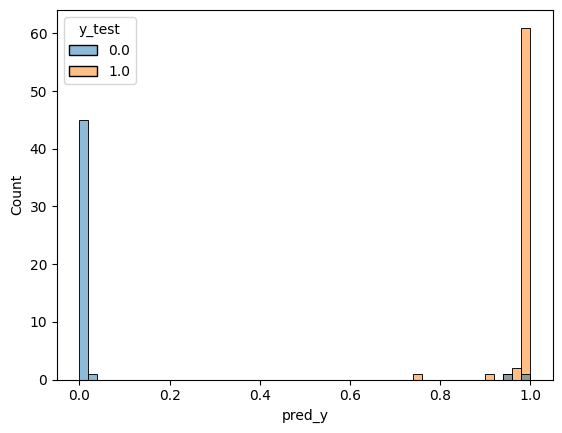

In [111]:
# 실제값은 명확하게 0,1로 표현
# 예측값은 확률값이 들어있어서 0~1 사이로 표현

sns.histplot(data=df, x = 'pred_y',hue = 'y_test', bins=50)
plt.show()
# 0과 1이 분류가 잘 되고 있음
# 3% 오류가 있었던 것은 히스토그램 막대표를 통해 확인 가능